# Minimum weight perfect matching implementation

**Reference paper**: https://arxiv.org/pdf/2105.13082

### First implementation: k=1 repetition code

Num qubits `n=3`; check matrix `H=[[1, 1, 0]; [0, 1, 1]]` rank 2; `n - rank(H) = 1` data qubit

We use `stim` repetition code simulator with a `Matching` object we define from our known check matrix 

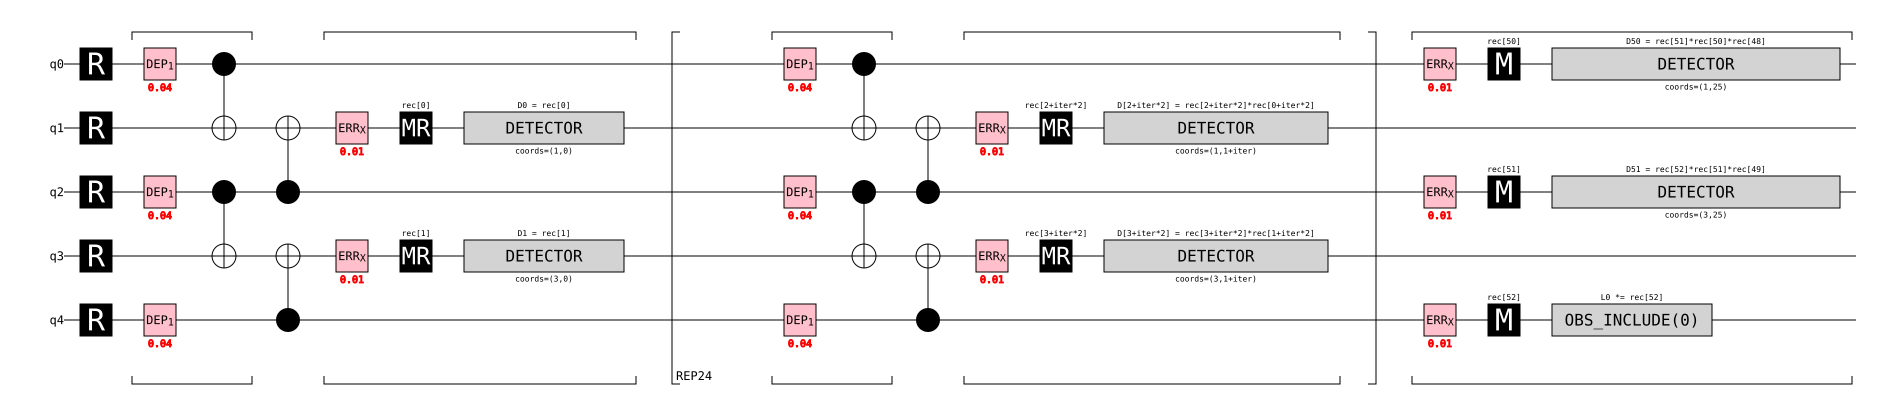

In [8]:
# construct stim simulator for data generation. repetition code circuit d=3
import stim
repetition_ckt = stim.Circuit.generated(
    "repetition_code:memory",
    rounds=25,
    distance=3,
    before_measure_flip_probability=0.01,
    before_round_data_depolarization=0.04
)
repetition_ckt.diagram('timeline-svg')

In [ ]:
# show errors as 1 when simulating the circuit. tracks each channel
sampler = repetition_ckt.compile_sampler()
result = sampler.sample(shots=3)[0]
print("".join("1" if e else "_" for e in result))

_1__________11_111111_1__1_1_1_1_1_111_111_1_1_1_111_


In [ ]:
# now show errors tracking the detector
# results are much more sparse because we are tracking detected errors, not just whether error happens or not on channel
# foundation for error correction: flips come in pairs
detector_sampler = repetition_ckt.compile_detector_sampler()
result = detector_sampler.sample(shots=3)[0]
print("".join("1" if e else "_" for e in result))

11________________________11________________________


## Matching decoder initialization

Now we initialize a detector error model (DEM) directly from the circuit data, and use it to construct a `pymatching.Matching` graph that encodes the syndrome data from the circuit as a MWPM graph

In [77]:
from pymatching import Matching

def mwpm_from_dem(meas_err_rate: float, data_err_rate: float, suppress_results: bool = False):
    repetition_ckt = stim.Circuit.generated(
        "repetition_code:memory",
        rounds=25,
        distance=3,
        before_measure_flip_probability=meas_err_rate,
        before_round_data_depolarization=data_err_rate,
    )
    dem = repetition_ckt.detector_error_model(decompose_errors=True)
    detection_events, observable_flips = detector_sampler.sample(shots=10**3, separate_observables=True)

    m = Matching.from_detector_error_model(dem)
    predictions = m.decode_batch(detection_events)

    prediction_errors = 0
    for i, flip in enumerate(observable_flips):
        if predictions[i] != flip:
            prediction_errors += 1

    prediction_error_rate = round(prediction_errors / len(predictions), 3)
    if not suppress_results:
        print(f"MWPM error rate: {prediction_error_rate}")
        print(f"Missed {prediction_errors} / {len(predictions)} detector errors.")

    return prediction_error_rate

error_rate = mwpm_from_dem(0.04, 0.01)

MWPM error rate: 0.123
Missed 123 / 1000 detector errors.


MWPM does pretty good with low error rate. Now let's vary error rate and see results

20
20
20
20


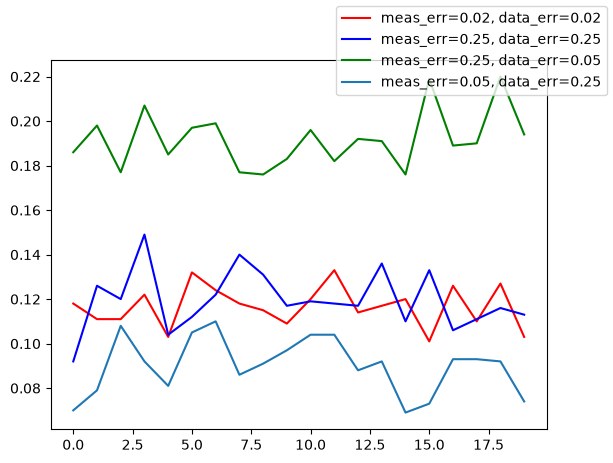

In [ ]:
import matplotlib.pyplot as plt

def run_mwpm(meas_err_rate: float, data_err_rate: float, num_shots: int = 20):
    results = []
    for i in range(num_shots):
        prediction_error_rate = mwpm_from_dem(meas_err_rate, data_err_rate, suppress_results=True)
        results.append(prediction_error_rate)
    return results

both_low = run_mwpm(0.02, 0.02)
both_high = run_mwpm(0.25, 0.25)
high_low = run_mwpm(0.25, 0.05)
low_high = run_mwpm(0.05, 0.25)

fig, ax = plt.subplots()
ax.plot(both_low, label="meas_err=0.02, data_err=0.02", color='r')
ax.plot(both_high, label="meas_err=0.25, data_err=0.25", color='b')
ax.plot(high_low, label="meas_err=0.25, data_err=0.05", color='g')
ax.plot(low_high, label="meas_err=0.05, data_err=0.25")
fig.legend(loc='outside right upper')